# Peripheral wall choice: a geometric race model

Central models beat peripheral models in every tournament so far. Human peripheral players, by contrast, score at about the same rate as human central players. This notebook asks how much of that could come from wall choice alone, using only arena geometry.

**Question.** A peripheral agent races a central agent that waits at the centre and always goes High. How do both agents' score rates change if the peripheral agent follows each of these rules?
1. Always move to the High wall.
2. Always move to the closest lit wall.
3. Move to High, unless High takes more than Δ seconds longer to reach than Low. Then move to the closest wall.

**Plan**
1. Inputs from the logs (speed, and the fixed time per trial outside the race).
2. Peripheral slice-onset positions.
3. Travel times to High and Low from those positions, against the central agent's.
4. Score rate as the threshold Δ changes.
5. The three rules side by side, including the margin over the opponent.
6. The three rules for each peripheral model.
7. How central agents turn to face High in the logs. These are the inputs for the central field of view, which sections 3-6 do not include yet.

**Choices and assumptions**
- Geometry only (user's choice). Each agent's time to a wall is its shortest path to the wall's trigger divided by the speed. No start-up delay and no timing noise, as neither is justified by geometry.
- Visibility of walls and of the opponent is ignored for now. Both agents know both lit walls at slice onset (user's choice, to be added later).
- The central agent waits at the exact centre and always goes High. Its behaviour never changes: only the peripheral agent's rule (and its threshold Δ) varies. The central agent's *score* still changes with the peripheral rule, because it depends on how many races the central agent wins. The fixed reference is central-vs-central play. 260929 central models took High on 0.998 of 5,344 won trials, and on 0.975 even when Low was more than 6 units nearer (checked 2026-10-19). This does not test lost trials, where the destination is not logged.
- Peripheral positions are the logged slice-onset positions of the 260929 peripheral models (mean onset centrality below 0.5). Each position meets all 40 layouts.
- Layouts follow `OctagonArenaSettings.cs`. High is uniform over the 8 walls. Low is 1, 2 or 4 walls away (weights 0.5/0.25/0.25) on a random side.
- An agent whose body overlaps a lit trigger at slice onset wins that wall at once, whatever its rule (game rule).
- Neither agent blocks the other. Equal travel times split the win.
- Score per second is the primary measure (players are told to maximise score over time). It is total expected score over total expected trial time. Trial time is the race plus the fixed time per trial outside it (trial start to slice onset, trigger to trial end, and the ITI). Score per trial is secondary.
- Relative score is also reported (user's choice). It is the peripheral agent's score per second minus its opponent's. Human players may try to beat the other player as well as to maximise their own score. A central player facing a central opponent ties every race, so its margin is 0.
- Trials follow the repo convention (first logged trial dropped, incomplete final trial dropped). Agent sims have no spawn trial at the arena centre.

**Modules.** All numbers come from `analysis/analytical_race.py`. The geometry and the race scoring are checked against hand-counted answers in `tests/test_analytical_race.py` (20 tests). For example, from the eight alcove backs, "always High" wins 7/16 of trials and scores 0.3625 per trial, and "closest" scores 0.425. Decisions are logged in `READMEs/analytical_modelling_notes.md`.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import data_strings
import data_extraction.data_saving as data_saving
import analysis.analytical_race as ar

RECOMPUTE = False                   # rebuild the cached tables
BATCH = '260929'
SIM_DATA_FOLDER = os.path.join(data_strings.SIM_DATA_FOLDER, '2609', BATCH)
CUT = 0.5                           # peripheral below this mean onset centrality
DELTAS = np.round(np.arange(0, 3.81, 0.05), 2)     # thresholds swept (s); 3.8 s is the longest gap possible

# colours: peripheral agent and its rules in fixed order, central agent in grey
C_HIGH, C_CLOSEST, C_THRESH, C_CENTRAL = '#2a78d6', '#eb6834', '#1baf7a', '#6b6b6b'
C_PERIPH = C_HIGH

## 1. Inputs from the logs

**Motivation.** The model needs two numbers from the game: how fast an agent moves, and how much time each trial costs outside the race. Both are measured from 260929 self-play.

**Method.** For five central models, take each trial's median moving speed (both agents, slice onset to trigger, frames moving faster than 0.5 units/s) and its overhead.

**Terms**
- Moving speed in units/s. The code sets `moveSpeed` to 10.
- `overhead_s` is the whole trial length less the slice-onset-to-trigger time, in seconds. It covers trial start to slice onset, trigger to trial end, and the ITI. These delays were set to match the human task.

**Choices.** The mean overhead is used for every trial, whatever the outcome (sd shown in the figure).

**How to read the figure.** Left: one count per trial, the trial's median moving speed. Right: one count per trial, its overhead. The dashed line and its label give the value used in the model.

**Why it is plotted.** The speed should sit at 10 in every trial, so that path length converts directly to time. The overhead spread shows how far a single fixed value is from the real trials.

trial_timing_260929_central5: loaded from cache


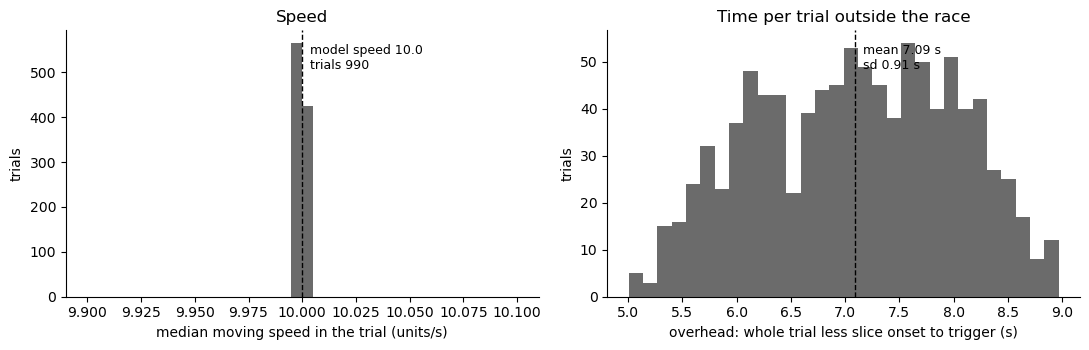

In [2]:
# split the batch by mean onset centrality
tables = data_saving.load_data(f'model_characterisation_{BATCH}', data_saving.cache_dir)['result']
centrality = tables['slice'].groupby('model')['centrality'].mean()
PERIPHERAL = sorted(centrality[centrality < CUT].index)
CENTRAL = sorted(centrality[centrality >= CUT].index)

# get per-trial speed and overhead for five central models
timing_df = data_saving.cached(f'trial_timing_{BATCH}_central5',
                               lambda: ar.collect_trial_timing(SIM_DATA_FOLDER, CENTRAL[:5], verbose=False),
                               recompute=RECOMPUTE, stamp=(tuple(CENTRAL[:5]), 'v2'))
OVERHEAD = timing_df['overhead_s'].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.hist(timing_df['speed_median'], bins=np.linspace(9.9, 10.1, 41), color=C_CENTRAL)
ax.axvline(ar.SPEED, color='black', ls='--', lw=1)
ax.text(ar.SPEED, ax.get_ylim()[1] * 0.95, f"  model speed {ar.SPEED:.1f}\n  trials {len(timing_df)}", va='top', fontsize=9)
ax.set_xlabel('median moving speed in the trial (units/s)')
ax.set_ylabel('trials')
ax.set_title('Speed')
ax = axes[1]
ax.hist(timing_df['overhead_s'], bins=30, color=C_CENTRAL)
ax.axvline(OVERHEAD, color='black', ls='--', lw=1)
ax.text(OVERHEAD, ax.get_ylim()[1] * 0.95, f"  mean {OVERHEAD:.2f} s\n  sd {timing_df['overhead_s'].std():.2f} s",
        va='top', fontsize=9)
ax.set_xlabel('overhead: whole trial less slice onset to trigger (s)')
ax.set_ylabel('trials')
ax.set_title('Time per trial outside the race')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## 2. Peripheral slice-onset positions

**Motivation.** A peripheral agent's start position decides every travel time in the model. This section shows where the peripheral models actually wait.

**Method.** Take both agents' slice-onset positions on every trial of each peripheral model (first logged trial dropped).

**Terms**
- Onset radius is the distance from the arena centre in units. The alcove back is at 19.75 and the wall face at 16.75.
- The trigger line (18.25) is where an agent's body first overlaps a trigger box. An agent beyond it, inside a lit alcove, wins at once.

**How to read the figure.** Left: the reachable space (grey outline), one dot per agent-trial at slice onset (blue, semi-transparent), and the central agent's fixed start (black). Right: the onset radius of the same positions, with the trigger line, wall face and alcove back marked in the panel.

**Why it is plotted.** Positions past the trigger line can win their own alcove instantly. Positions short of it, such as the alcove mouth, have to move even to reach their own wall. That changes which rule is best.

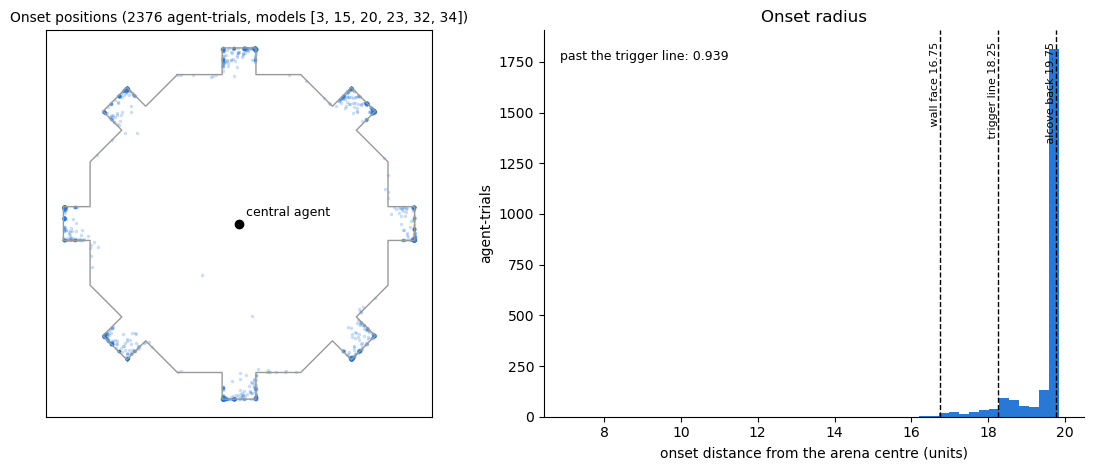

In [3]:
# get the peripheral onset positions from the race table (both agents, first trial already dropped)
race_df = data_saving.load_data(f'race_table_{BATCH}', data_saving.cache_dir)['result']
periph = race_df[race_df['model'].isin(PERIPHERAL)].reset_index(drop=True)
pos = periph[['x', 'z']].to_numpy(float)
radius = np.hypot(pos[:, 0], pos[:, 1])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw=dict(width_ratios=[1, 1.2]))
ax = axes[0]
poly = np.vstack([ar.reach_polygon(), ar.reach_polygon()[:1]])
ax.plot(poly[:, 0], poly[:, 1], color='#999999', lw=1)
ax.scatter(pos[:, 0], pos[:, 1], s=6, color=C_PERIPH, alpha=0.25, lw=0)
ax.plot(0, 0, 'ko', ms=6)
ax.text(0.8, 0.8, 'central agent', fontsize=9)
ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
ax.set_title(f'Onset positions ({len(pos)} agent-trials, models {PERIPHERAL})', fontsize=10)
ax = axes[1]
ax.hist(radius, bins=np.linspace(radius.min() - 0.1, 19.85, 50), color=C_PERIPH)
for r, lab in ((ar.W, 'wall face'), (ar.TRIGGER_REACH, 'trigger line'), (ar.BACK, 'alcove back')):
    ax.axvline(r, color='black', ls='--', lw=1)
    ax.text(r, ax.get_ylim()[1] * 0.97, f' {lab} {r:.2f}', rotation=90, va='top', ha='right', fontsize=8)
past = (radius >= ar.TRIGGER_REACH).mean()
ax.text(0.03, 0.95, f"past the trigger line: {past:.3f}", transform=ax.transAxes, va='top', fontsize=9)
ax.set_xlabel('onset distance from the arena centre (units)')
ax.set_ylabel('agent-trials')
ax.set_title('Onset radius')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## 3. Travel times to High and Low

**Motivation.** A rule can only change the outcome where the walls differ in whether they can be reached first. This section shows how often each case occurs.

**Method.** Pair every peripheral position with all 40 layouts. Take the peripheral agent's travel time to High and to Low, and the central agent's travel time to High. Weight each pair by its layout probability, with every position counting equally.

**Terms**
- `t_high`, `t_low`: peripheral shortest path to that wall's trigger / 10 units/s, in seconds. 0 = already on the trigger.
- Central time: 18.25 / 10 = 1.82 s to any wall, from the centre.
- A wall is winnable when the peripheral time to it is below the central time.

**How to read the figure.** Each cell is a combination of peripheral time to High (x) and to Low (y). Shading is the probability of that combination (darker = more likely, log scale). The dashed lines mark the central agent's time, splitting the panel into four regions. The label in each region gives its total probability. The dotted diagonal marks equal times.

**Why it is plotted.** "Only Low winnable" (bottom right) is where heading Low adds score that "always High" misses. "Both winnable" is where heading Low throws away a High win. All three rules agree in "neither winnable" and "only High winnable", unless the rule sends the agent to a losing Low.

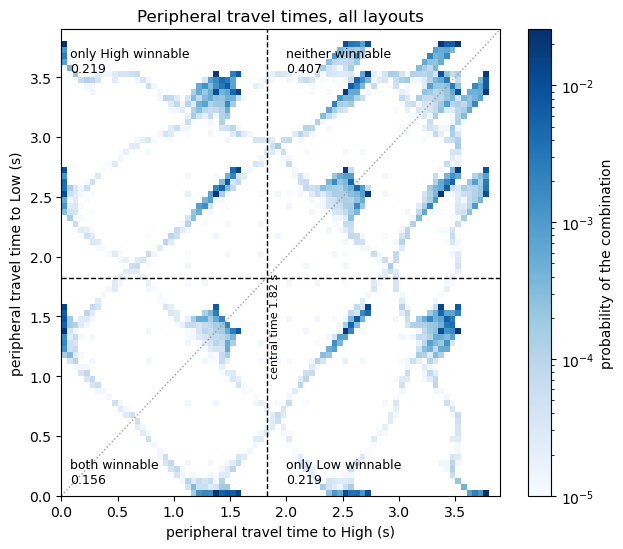

In [4]:
# build the races once per model (each model weighs its own positions equally) and pooled (every position equal)
races = ar.build_races(pos, groups=periph['model'].to_numpy())
pooled = races.assign(group=0, prob=races['prob'] * races.groupby('group')['pos'].transform('nunique') / len(pos))
w = pooled['prob'].to_numpy()
tC = ar.TRIGGER_REACH / ar.SPEED
tH, tL = races['t_high'].to_numpy(), races['t_low'].to_numpy()
regions = {'both winnable': (tH < tC) & (tL < tC), 'only High winnable': (tH < tC) & (tL >= tC),
           'only Low winnable': (tH >= tC) & (tL < tC), 'neither winnable': (tH >= tC) & (tL >= tC)}
share = {k: w[m].sum() for k, m in regions.items()}

fig, ax = plt.subplots(figsize=(6.4, 5.6))
bins = np.linspace(0, 3.9, 79)
h, xe, ye = np.histogram2d(tH, tL, bins=[bins, bins], weights=w)
im = ax.pcolormesh(xe, ye, np.ma.masked_equal(h.T, 0), cmap='Blues',
                   norm=plt.matplotlib.colors.LogNorm(vmin=1e-5, vmax=h.max()))
ax.axvline(tC, color='black', ls='--', lw=1); ax.axhline(tC, color='black', ls='--', lw=1)
ax.plot([0, 3.9], [0, 3.9], color='#999999', ls=':', lw=1)
for k, (x, y) in {'both winnable': (0.08, 0.08), 'only High winnable': (0.08, 3.75),
                  'only Low winnable': (2.0, 0.08), 'neither winnable': (2.0, 3.75)}.items():
    ax.text(x, y, f"{k}\n{share[k]:.3f}", va='bottom' if y < 1 else 'top', fontsize=9)
ax.text(tC + 0.03, 1.0, f'central time {tC:.2f} s', rotation=90, fontsize=8)
ax.set_xlabel('peripheral travel time to High (s)')
ax.set_ylabel('peripheral travel time to Low (s)')
ax.set_title('Peripheral travel times, all layouts')
fig.colorbar(im, ax=ax, label='probability of the combination')
plt.tight_layout(); plt.show()

## 4. Score rate as the threshold changes

**Motivation.** Rule 3 depends on its threshold Δ. Sweeping Δ shows which values work best, and how the rule moves between "closest" and "always High".

**Method.** For Δ from 0 to 3.8 s (step 0.05), apply rule 3 to every position and layout, and compute both agents' expected scores.

**Terms**
- Δ: the extra travel time to High (over Low) at which the peripheral agent gives up on High, in seconds. Δ belongs to the peripheral rule only. The central agent goes High from the centre (1.82 s) at every Δ. Δ = 0 is "closest". Δ ≥ 3.8 s is "always High", as no gap is longer.
- Score per second: total expected score / total expected trial time, with trial time = race + overhead.
- Share heading Low: fraction of trials in which the rule sends the agent to Low. Instant wins count by the rule's choice.
- Central score: the central agent's behaviour is fixed, so its score moves only because the peripheral agent wins more or fewer races. Per trial it equals 1 − the peripheral win share (every central win is at High). Per second it also shifts slightly with race length.
- Central vs central: both agents at the centre going High, so every race ties (0.5 per trial). It does not depend on Δ, and is the fixed reference for a central player.

**How to read the figure.** x is Δ in all panels. Left: score per second for the peripheral agent (blue) and the central agent (grey). The grey line moves only because the peripheral rule changes who wins; central behaviour is the same at every Δ. The dashed line is central vs central (both at the centre, every race tied), the fixed reference. Middle: the same for score per trial. Right: the share of trials in which the peripheral agent heads for Low. The dotted vertical line marks the Δ with the highest peripheral score per second, labelled in the panel.

**Why it is plotted.** Steps in the curves happen where Δ passes the time gap of a common layout. A wide flat top means the exact threshold matters little.

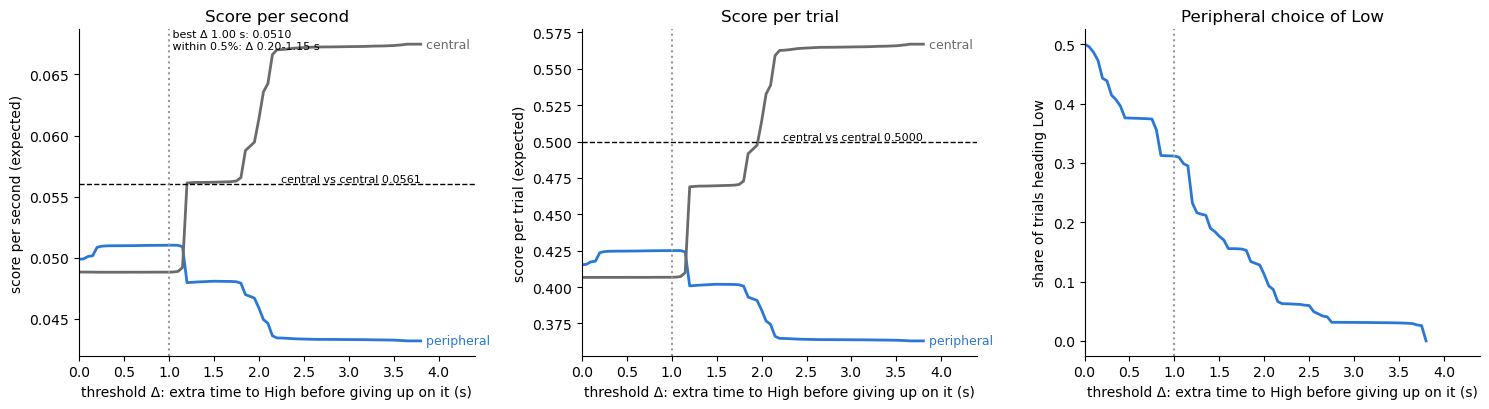

In [5]:
sweep = pd.concat([ar.summarise(pooled, OVERHEAD, 'threshold', d) for d in DELTAS], ignore_index=True)
best = sweep.iloc[sweep['periph_score_s'].to_numpy().argmax()]
D_BEST = float(best['delta'])
# find the flat top (within 0.5% of the best peripheral score per second)
top = sweep.loc[sweep['periph_score_s'] >= 0.995 * best['periph_score_s'], 'delta']
ref = ar.central_reference(OVERHEAD)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (p, c, ylab, r) in zip(axes[:2], (('periph_score_s', 'central_score_s', 'score per second', ref['score_s']),
                                         ('periph_score_trial', 'central_score_trial', 'score per trial', ref['score_trial']))):
    ax.plot(sweep['delta'], sweep[p], color=C_PERIPH, lw=2)
    ax.plot(sweep['delta'], sweep[c], color=C_CENTRAL, lw=2)
    ax.axhline(r, color='black', ls='--', lw=1)
    ax.text(3.8, r, f'central vs central {r:.4f}', ha='right', va='bottom', fontsize=8)
    ax.text(3.82, sweep[p].iloc[-1], ' peripheral', va='center', fontsize=9, color=C_PERIPH)
    ax.text(3.82, sweep[c].iloc[-1], ' central', va='center', fontsize=9, color=C_CENTRAL)
    ax.set_ylabel(f'{ylab} (expected)')
ax = axes[2]
ax.plot(sweep['delta'], sweep['p_go_low'], color=C_PERIPH, lw=2)
ax.set_ylabel('share of trials heading Low')
for ax in axes:
    ax.axvline(D_BEST, color='#999999', ls=':', lw=1.5)
    ax.set_xlabel('threshold Δ: extra time to High before giving up on it (s)')
    ax.set_xlim(0, 4.4)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].text(D_BEST, axes[0].get_ylim()[1], f" best Δ {D_BEST:.2f} s: {best['periph_score_s']:.4f}\n"
             f" within 0.5%: Δ {top.min():.2f}-{top.max():.2f} s", va='top', fontsize=8)
axes[0].set_title('Score per second')
axes[1].set_title('Score per trial')
axes[2].set_title('Peripheral choice of Low')
plt.tight_layout(); plt.show()

## 5. The three rules side by side

**Motivation.** This answers the question directly, for the pooled peripheral positions. Players may care about beating the other player as well as about their own score. So the margin over the opponent is shown beside the two score measures. It compares going peripheral (under each rule) with going central, against the same central opponent.

**Method.** Compute both agents' scores under "always High", "closest" and "threshold" (at the best Δ from section 4).

**Terms**
- Margin over the opponent: peripheral score per second minus central score per second. Positive = the peripheral agent finishes ahead.
- Central strategy margin: a central player against the same central opponent ties every race, so its margin is 0. Its own score is the central-vs-central value.

**How to read the figure.** One column per rule. Blue dots are the peripheral agent, grey dots its central opponent, each labelled with its value. The central agent behaves the same under every rule; its dot moves only because the peripheral rule changes who wins. The dashed line is central vs central, the fixed reference for a central player. Left: score per second. Middle: score per trial. Right: the peripheral agent's margin over its opponent per second (blue dots, labelled). The dashed line at 0 is the margin a central player gets against the same opponent.

**Why it is plotted.** The left two panels show how far each rule moves the peripheral agent toward, or past, the central agent and central-vs-central play, and what the central agent loses in return. The right panel shows whether going peripheral leaves a player further ahead of a central opponent than going central would. If its dots sit above 0, a player who cares about relative score does better by going peripheral, even when its own score per second is lower.

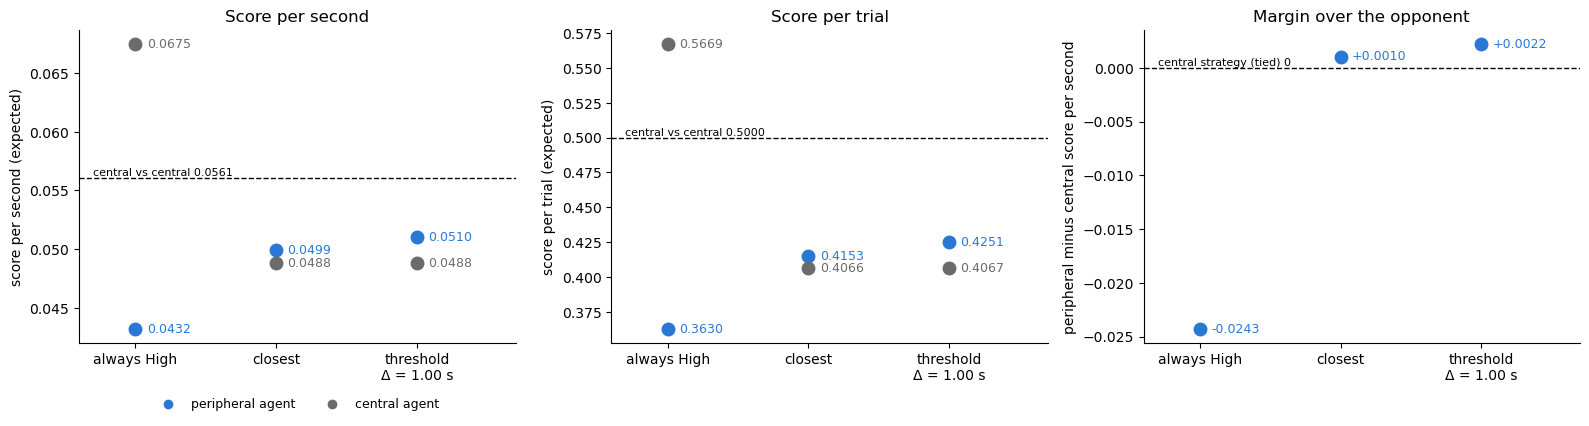

In [6]:
RULES = [('always High', 'high', None), ('closest', 'closest', None), (f'threshold\nΔ = {D_BEST:.2f} s', 'threshold', D_BEST)]
rules = pd.concat([ar.summarise(pooled, OVERHEAD, pol, d).assign(rule=lab) for lab, pol, d in RULES],
                  ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, (p, c, ylab, r) in zip(axes[:2], (('periph_score_s', 'central_score_s', 'score per second', ref['score_s']),
                                      ('periph_score_trial', 'central_score_trial', 'score per trial', ref['score_trial']))):
    x = np.arange(len(rules))
    ax.plot(x, rules[p], 'o', color=C_PERIPH, ms=9)
    ax.plot(x, rules[c], 'o', color=C_CENTRAL, ms=9)
    for xi, vp, vc in zip(x, rules[p], rules[c]):
        ax.text(xi + 0.08, vp, f'{vp:.4f}', va='center', fontsize=9, color=C_PERIPH)
        ax.text(xi + 0.08, vc, f'{vc:.4f}', va='center', fontsize=9, color=C_CENTRAL)
    ax.axhline(r, color='black', ls='--', lw=1)
    ax.text(-0.3, r, f'central vs central {r:.4f}', va='bottom', fontsize=8)
    ax.set_xticks(x, rules['rule'])
    ax.set_xlim(-0.4, len(rules) - 0.3)
    ax.set_ylabel(f'{ylab} (expected)')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].plot([], [], 'o', color=C_PERIPH, label='peripheral agent')
axes[0].plot([], [], 'o', color=C_CENTRAL, label='central agent')
axes[0].legend(frameon=False, fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2)
axes[0].set_title('Score per second')
axes[1].set_title('Score per trial')
# plot the peripheral margin over the opponent, against the central strategy's tie
ax = axes[2]
margin = rules['periph_score_s'] - rules['central_score_s']
x = np.arange(len(rules))
ax.plot(x, margin, 'o', color=C_PERIPH, ms=9)
for xi, v in zip(x, margin):
    ax.text(xi + 0.08, v, f'{v:+.4f}', va='center', fontsize=9, color=C_PERIPH)
ax.axhline(0, color='black', ls='--', lw=1)
ax.text(-0.3, 0, 'central strategy (tied) 0', va='bottom', fontsize=8)
ax.set_xticks(x, rules['rule'])
ax.set_xlim(-0.4, len(rules) - 0.3)
ax.set_ylabel('peripheral minus central score per second')
ax.spines[['top', 'right']].set_visible(False)
ax.set_title('Margin over the opponent')
plt.tight_layout(); plt.show()

## 6. The three rules for each peripheral model

**Motivation.** The pooled result could hide models whose waiting positions differ. This section repeats section 5 for each model's own positions.

**How to read the figure.** One column per peripheral model. Dots are the peripheral agent's score per second under each rule (colours in the legend). The grey crosses are the central opponent's score when the peripheral agent plays "always High" and "threshold" (central behaviour is the same in both). The dashed line is central vs central, the fixed reference.

**Why it is plotted.** If the dots line up across models, the result depends on where peripheral models wait in general, not on any one model.

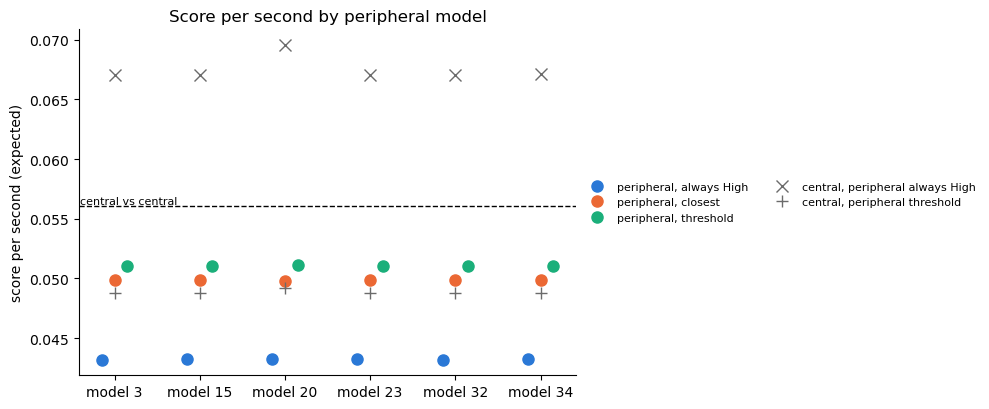

In [7]:
per_model = pd.concat([ar.summarise(races, OVERHEAD, pol, d).assign(rule=lab.split('\n')[0]) for lab, pol, d in RULES],
                      ignore_index=True)

fig, ax = plt.subplots(figsize=(10, 4.2))
models = sorted(per_model['group'].unique())
for k, (rule, col) in enumerate(zip(('always High', 'closest', 'threshold'), (C_HIGH, C_CLOSEST, C_THRESH))):
    s = per_model[per_model['rule'] == rule].set_index('group').loc[models]
    ax.plot(np.arange(len(models)) + (k - 1) * 0.15, s['periph_score_s'], 'o', color=col, ms=8, label=f'peripheral, {rule}')
for rule, mk in (('always High', 'x'), ('threshold', '+')):
    s = per_model[per_model['rule'] == rule].set_index('group').loc[models]
    ax.plot(np.arange(len(models)), s['central_score_s'], mk, color=C_CENTRAL, ms=9, label=f'central, peripheral {rule}')
ax.axhline(ref['score_s'], color='black', ls='--', lw=1)
ax.text(-0.4, ref['score_s'], 'central vs central', ha='left', va='bottom', fontsize=8)
ax.set_xticks(np.arange(len(models)), [f'model {m}' for m in models])
ax.set_ylabel('score per second (expected)')
ax.legend(frameon=False, fontsize=8, ncol=2, loc='center left', bbox_to_anchor=(1.0, 0.5))
ax.spines[['top', 'right']].set_visible(False)
ax.set_title('Score per second by peripheral model')
plt.tight_layout(); plt.show()

## 7. Central agents turning to face High (logs)

**Motivation.** The next version of the model gives the central agent its ray sensor. It must turn to face High before travelling straight to it, and it can close on High while turning once High is in view. This section measures how central agents do this in the logs. It sets the model's turning rate and closing speed, and records where the model's turn differs from what agents do.

**Method.** For every agent-trial of five central 260929 models (1, 2, 4, 5, 6; both agents), follow the agent from slice onset until it faces High within ±10°. Agent-trials that never face High before the trigger, or face it at onset, are left out.

**Terms**
- Angle to High (φ): High's bearing from the agent minus its heading at onset, 0-180°.
- Sensed (in view): at least one of the agent's 7 rays (0, ±18.3, ±36.7, ±55° from the heading, first hit only) hits any part of High or its trigger box. This uses `analysis/agent_raycast.py`, the replica of the agents' sensor. From the centre, High is sensed when φ < 77.5° (the ±55° ray reaching High's vertex). In these 260929 logs, player 1's rays are blocked by player 0's body (builds before 261014). This changes sensing at onset in 1.1% of player-1 agent-trials. The model's rays pass through the opponent, as in current builds.
- Turning rate: total heading change, counting back-and-forth, over the time to face High (°/s). The rate while rotating counts only frames where the heading changed by more than 0.5°.
- Short way: the agent's net turn went the shorter way round to High. 0.5 = no better than a random direction.
- Rotating / still time: time in frames with / without a heading change above 0.5°.
- Closing speed: reduction in straight-line distance to High's trigger line in frames with High in view before facing it, over the time in those frames (units/s).

**Choices and assumptions**
- The model's turning rate is the median per-agent-trial turning rate (user's choice). It reflects how fast agents turn while they are turning.
- The model's agent turns straight to High, with no back-and-forth. It turns the short way when High is in view at onset, and in a random direction when it is not (user's choice). The logged short-way bias is likely due to inferring High from the Low wall's position (user). That is not in the model yet.
- The model's agent moves only while High is in view (user's choice), at the median closing speed. Logged agents also move while High is out of view.

**How to read the figure.**
- (a) Turning rate per agent-trial (bars). Lines mark the model's rate (median), the pooled rate while rotating, and the code maximum.
- (b) Short-way share by angle to High at onset (dots, with agent-trial counts), for High not sensed at onset. The dashed line is a random direction (0.5). The square is the share when High is in view at onset.
- (c) Mean time to face High, split into rotating (dark) and still (light), for the logs and the model, with High in view or out of view at onset.
- (d) Mean angle turned to face High. Logs: net angle, and total angle counting back-and-forth. Model: the angle it turns.
- (e) Closing speed per agent-trial (bars). Lines mark the model's value (median) and full speed (10 units/s). The text gives the mean distance moved, and how much closer to High the agent got, before facing High.
- (f) Mean race time from slice onset to trigger in central-vs-central play (the faster agent): logs, model with turn-then-move, and model with moving while turning. The dashed line is straight travel from the centre with no turn.

**Why it is plotted.** Panels (a) and (e) set the model's two new inputs and show how consistent they are. Panels (b) to (d) show what agents do that the model leaves out (turning toward High more often than chance, turning back and forth, pausing). Panel (f) shows the net effect of these choices on race time.

central_alignment_260929_central5: loaded from cache


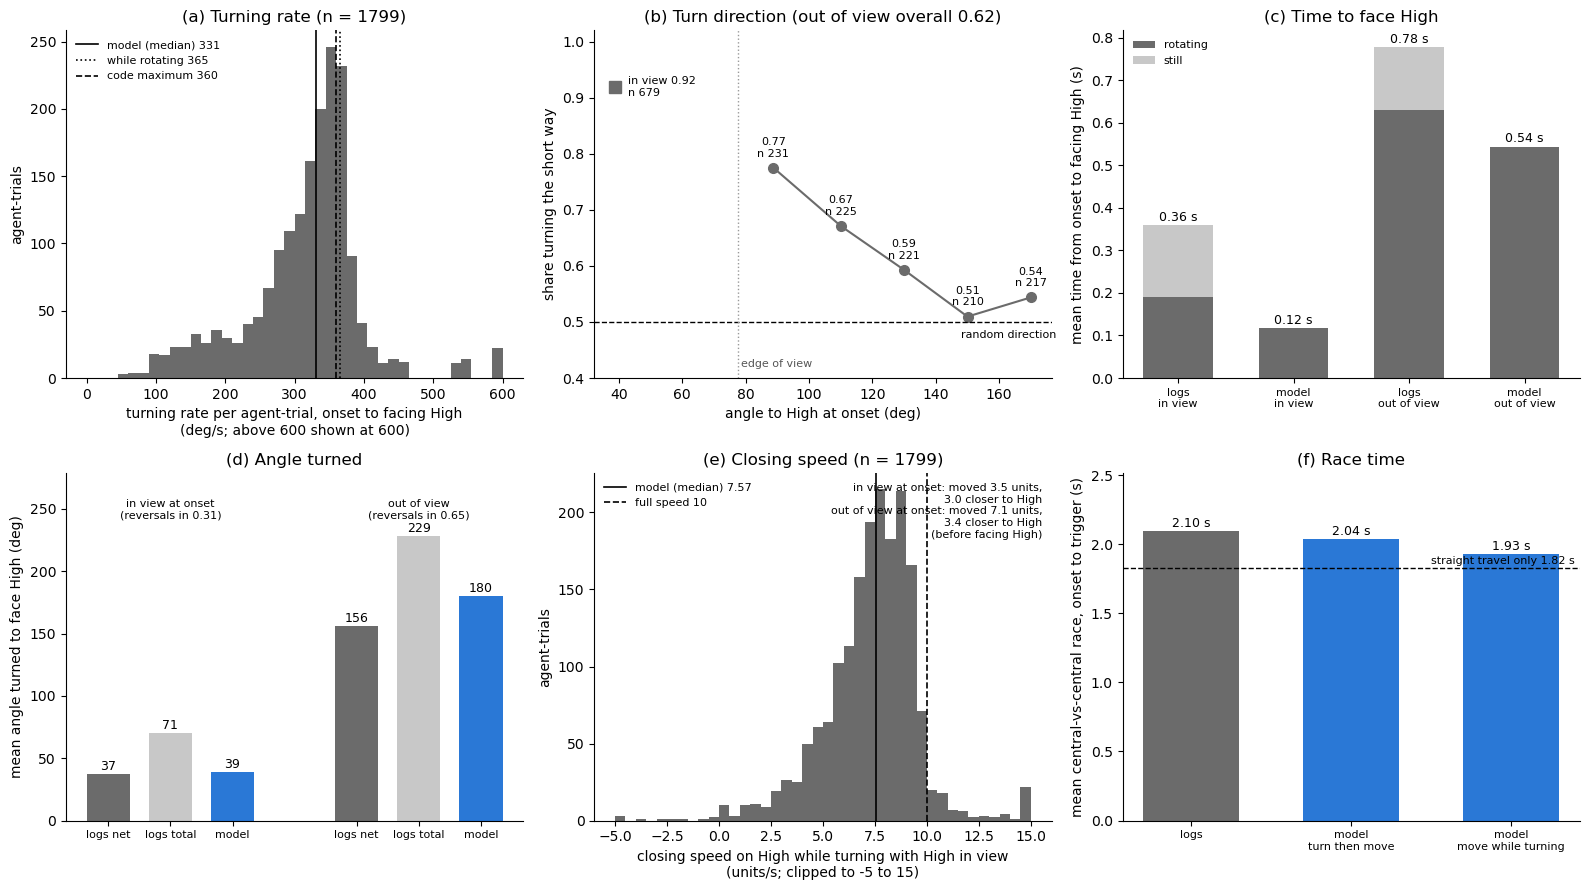

In [8]:
# get how each central agent-trial turns to face High
alignment = data_saving.cached(f'central_alignment_{BATCH}_central5',
                               lambda: ar.collect_central_alignment(SIM_DATA_FOLDER, CENTRAL[:5], verbose=False),
                               recompute=RECOMPUTE, stamp=(tuple(CENTRAL[:5]), ar.ALIGN_TOL, 'rays', 'v4'))
ROT = ar.rotation_speed(alignment)
CLOSE = ar.closing_speed(alignment)
ok = alignment[alignment['t_align'] > 0]
inv, outv = ok[ok['visible']], ok[~ok['visible']]
V = ar.central_visible_half_angle()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
# (a) turning rate per agent-trial
ax = axes[0, 0]
rate = ok['turned'] / ok['t_align']
ax.hist(rate.clip(upper=600), bins=np.arange(0, 610, 15), color=C_CENTRAL)
rot_pooled = ok['turned'].sum() / ok['t_rotating'].sum()
for v, lab, ls in ((ROT, f'model (median) {ROT:.0f}', '-'), (rot_pooled, f'while rotating {rot_pooled:.0f}', ':'),
                   (360, 'code maximum 360', '--')):
    ax.axvline(v, color='black', ls=ls, lw=1.2, label=lab)
ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.set_xlabel('turning rate per agent-trial, onset to facing High\n(deg/s; above 600 shown at 600)')
ax.set_ylabel('agent-trials')
ax.set_title(f'(a) Turning rate (n = {len(ok)})')

# (b) short-way share by angle to High, out of view
ax = axes[0, 1]
bins = [V, 100, 120, 140, 160, 180]
grp = outv.groupby(pd.cut(outv['phi'].abs(), bins), observed=True)['short_way']
mids = [(a + b) / 2 for a, b in zip(bins[:-1], bins[1:])]
ax.plot(mids, grp.mean().to_numpy(), 'o-', color=C_CENTRAL, ms=7)
for x, m, n_ in zip(mids, grp.mean(), grp.size()):
    ax.text(x, m + 0.02, f'{m:.2f}\nn {n_}', ha='center', fontsize=8)
in_short = inv['short_way'].astype(float).mean()
ax.plot(V / 2, in_short, 's', color=C_CENTRAL, ms=8)
ax.text(V / 2 + 4, in_short, f'in view {in_short:.2f}\nn {len(inv)}', va='center', fontsize=8)
ax.axhline(0.5, color='black', ls='--', lw=1)
ax.text(178, 0.485, 'random direction', ha='right', va='top', fontsize=8)
ax.axvline(V, color='#999999', ls=':', lw=1)
ax.text(V + 1, 0.42, 'edge of view', fontsize=8, color='#555555')
ax.set_ylim(0.4, 1.02)
ax.set_xlabel('angle to High at onset (deg)')
ax.set_ylabel('share turning the short way')
ax.set_title(f"(b) Turn direction (out of view overall {outv['short_way'].astype(float).mean():.2f})")

# (c) time to face High, rotating vs still
ax = axes[0, 2]
model_turn = {'in view': (V / 2) / ROT, 'out of view': 180 / ROT}
labels, rot_t, still_t = [], [], []
for name, g in (('in view', inv), ('out of view', outv)):
    labels += [f'logs\n{name}', f'model\n{name}']
    rot_t += [g['t_rotating'].mean(), model_turn[name]]
    still_t += [g['t_still'].mean(), 0.0]
x = np.arange(len(labels))
ax.bar(x, rot_t, color=C_CENTRAL, width=0.6, label='rotating')
ax.bar(x, still_t, bottom=rot_t, color='#c8c8c8', width=0.6, label='still')
for xi, r_, s_ in zip(x, rot_t, still_t):
    ax.text(xi, r_ + s_ + 0.01, f'{r_ + s_:.2f} s', ha='center', fontsize=9)
ax.set_xticks(x, labels, fontsize=8)
ax.set_ylabel('mean time from onset to facing High (s)')
ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.set_title('(c) Time to face High')

# (d) angle turned
ax = axes[1, 0]
vals = [inv['net_turn'].abs().mean(), inv['turned'].mean(), V / 2,
        outv['net_turn'].abs().mean(), outv['turned'].mean(), 180.0]
labs = ['logs net', 'logs total', 'model', 'logs net', 'logs total', 'model']
xs = np.array([0, 1, 2, 4, 5, 6])
ax.bar(xs, vals, color=[C_CENTRAL, '#c8c8c8', C_PERIPH] * 2, width=0.7)
for xi, v in zip(xs, vals):
    ax.text(xi, v + 3, f'{v:.0f}', ha='center', fontsize=9)
ax.set_xticks(xs, labs, fontsize=8)
ax.text(1, max(vals) * 1.06, f"in view at onset\n(reversals in {(inv['reversals'] > 0).mean():.2f})", ha='center', fontsize=8)
ax.text(5, max(vals) * 1.06, f"out of view\n(reversals in {(outv['reversals'] > 0).mean():.2f})", ha='center', fontsize=8)
ax.set_ylim(0, max(vals) * 1.22)
ax.set_ylabel('mean angle turned to face High (deg)')
ax.set_title('(d) Angle turned')

# (e) closing speed per agent-trial
ax = axes[1, 1]
has_view = ok['t_inview'] > 0
cl = ok.loc[has_view, 'closing_inview'] / ok.loc[has_view, 't_inview']
ax.hist(cl.clip(-5, 15), bins=np.arange(-5, 15.25, 0.5), color=C_CENTRAL)
ax.axvline(CLOSE, color='black', lw=1.2, label=f'model (median) {CLOSE:.2f}')
ax.axvline(ar.SPEED, color='black', ls='--', lw=1.2, label=f'full speed {ar.SPEED:.0f}')
ax.legend(frameon=False, fontsize=8, loc='upper left')
# note how far agents move before facing High, in view and out of view at onset
ax.text(0.98, 0.97, '\n'.join(f"{n_} at onset: moved {g['path_moved'].mean():.1f} units,\n  {g['closer'].mean():.1f} closer to High"
                              for n_, g in (('in view', inv), ('out of view', outv))) + '\n(before facing High)',
        transform=ax.transAxes, ha='right', va='top', fontsize=8)
ax.set_xlabel('closing speed on High while turning with High in view\n(units/s; clipped to -5 to 15)')
ax.set_ylabel('agent-trials')
ax.set_title(f'(e) Closing speed (n = {len(cl)})')

# (f) central-vs-central race time
ax = axes[1, 2]
race_vals = [timing_df['rt_s'].mean(),
             ar.central_reference(OVERHEAD, central_t=ar.central_times(ROT))['race_s'],
             ar.central_reference(OVERHEAD, central_t=ar.central_times(ROT, close_speed=CLOSE))['race_s']]
labs = ['logs', 'model\nturn then move', 'model\nmove while turning']
ax.bar(range(3), race_vals, color=[C_CENTRAL, C_PERIPH, C_PERIPH], width=0.6)
for xi, v in enumerate(race_vals):
    ax.text(xi, v + 0.03, f'{v:.2f} s', ha='center', fontsize=9)
ax.axhline(ar.TRIGGER_REACH / ar.SPEED, color='black', ls='--', lw=1)
ax.text(2.4, ar.TRIGGER_REACH / ar.SPEED + 0.03, f'straight travel only {ar.TRIGGER_REACH / ar.SPEED:.2f} s', ha='right', fontsize=8)
ax.set_xticks(range(3), labs, fontsize=8)
ax.set_ylim(0, max(race_vals) * 1.2)
ax.set_ylabel('mean central-vs-central race, onset to trigger (s)')
ax.set_title('(f) Race time')
for a_ in axes.ravel():
    a_.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## Interpretation

**Inputs**
- Every one of the 990 measured trials has a median moving speed of 10.0 units/s (section 1). Path length therefore converts directly to time.
- The overhead is 7.09 s per trial (sd 0.91 s), against a race of at most 1.82 s. So score per second is driven mostly by score per trial.

**Where the choice matters (section 3)**
- 0.939 of peripheral onset positions are past the trigger line, mostly at the alcove back.
- Only Low is winnable in 0.219 of position-layouts. This is the score that "always High" leaves behind.
- Both walls are winnable in 0.156. Here, heading Low gives up a High win. Most of these are an adjacent High with the agent close to, but not on, its own Low trigger.
- In the remaining 0.626 (only High winnable 0.219, neither 0.407), the rules can only differ by sending the agent to a losing Low.

**The three rules (sections 4 and 5)**
- **Always High.** Peripheral 0.0432 score/s against central 0.0675 (score per trial 0.363 vs 0.567).
- **Closest.** Peripheral 0.0499 against central 0.0488 (+16% for the peripheral agent). The peripheral agent now out-scores its opponent.
- **Threshold.** The best Δ is 1.00 s, and any Δ from 0.20 to 1.15 s comes within 0.5% of it. It gives peripheral 0.0510 against central 0.0488 (+18% over always High). Score per trial is 0.425 vs 0.407.
- Why the threshold rule beats "closest": below Δ = 0.2 s, the agent gives up winnable Highs that are only slightly further than Low.
- Above Δ = 1.15 s, the agent stops taking the adjacent Low when High is two walls away (a 1.17 s gap). Its score drops to 0.048, and the central agent rises to 0.056.
- Even the best rule leaves the peripheral agent below central-vs-central play (0.0510 vs 0.0561, 91%). Head to head, though, it scores slightly more than the central agent (0.0510 vs 0.0488).

**Relative score (section 5, right panel)**
- Against a central opponent, going central ties (margin 0). Going peripheral gives a margin of +0.0010 per second with "closest" and +0.0022 with the threshold rule. With "always High" the margin is −0.0243.
- Peripheral play with a good wall rule costs the player some of its own score (0.0510 vs 0.0561). It costs the central opponent more (0.0488 vs 0.0561). A player trying to finish ahead of the other player therefore does better peripheral, while a player trying to maximise its own score does better central.
- The margin is small and depends on the wall rule. It is also a geometric upper limit, so visibility may remove it.

**By model (section 6).** All six peripheral models give the same scores under each rule (always High 0.043, closest 0.050, threshold 0.051). Model 20's central opponent scores more under "always High" (0.0695 vs 0.067 for the others). So the result depends on the general peripheral waiting position, not on any one model.

**Answer.** On geometry alone, a peripheral agent that keeps going High unless it is about 0.2-1.15 s further than Low scores 18% more per second than one that always goes High. It then out-scores a central opponent. Most of the gain is already captured by simply going to the closest wall (+16%).

**Limits**
- Both agents know both lit walls at onset and move along shortest paths at full speed from onset. Real peripheral agents can't see adjacent walls from the alcove back, so these are upper limits for the peripheral agent.
- The central agent's rule is checked on won trials only.
- The model says nothing yet about how human players choose, or how fast they move.

**Central agents turning to face High (section 7).** These are inputs for the next version of the model, not yet used in sections 3-6.
- Turning rate: median 331°/s per agent-trial (n 1,799). While actually rotating it is 365°/s, at the code maximum of 360°/s. The model uses 331°/s.
- Turn direction (High sensed by the rays or not): with High out of view, agents turn the short way on 0.62 of agent-trials. The share is 0.77 just outside the view (77.5-100°) and 0.51-0.54 when High is behind (140-180°). With High in view it is 0.92. The model turns at random when High is out of view. The bias is likely from inferring High from the Low wall's position (to be added later).
- Agents take longer to face High than the model's agent: 0.36 s vs 0.12 s with High in view, 0.78 s vs 0.54 s out of view. They turn back and forth (reversals in 0.31 and 0.65 of agent-trials). They turn 71° in total for a net 37° (in view) and 229° for a net 157° (out of view). They also spend 0.17 s and 0.15 s not rotating. Their net turn (157°) is smaller than the model's random-direction turn (180°), but the back-and-forth more than cancels this.
- Agents move while turning. Before facing High they move 3.5 units and get 3.0 closer to High (in view at onset), or 7.1 units and 3.4 closer (out of view). With High in view they close on it at a median 7.57 units/s (full speed 10). The model's agent closes at 7.57 units/s only while High is in view, and stands still while High is out of view.
- Net effect on race time: central-vs-central races last 2.10 s in the logs. The model gives 2.04 s with turn-then-move and 1.93 s with moving while turning (straight travel alone 1.82 s). The model's central agent is therefore 0.17 s faster than logged agents, because it turns without back-and-forth or pauses.